Hi, in this notebook I built a binary classifier model that determines whether a restaurant review is positive or negative. This model uses natural language processing techniques to preprocess the data and make the integer arrays, which are fed into our model to predict the sentiment of the fed-in reviews.


In [1]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import re, nltk, itertools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Data Preprocessing
When it comes to natural language processing, one of the challenging tasks is to convert the text data into numpy arrays. In the following 4 codeblocks, that's what I focused on and prepared the data. In the upcoming codeblock, I downloaded the stopword set from the NLTK library and removed the word "not," since it is widely used to represent negative restaurant reviews. And then I imported the dataset using Pandas.

In [2]:
# Download stopwords
nltk.download('stopwords')

# Exclude the word not in stopwords
modified_stopwords = set(stopwords.words('english'))
modified_stopwords.remove('not')

# Import dataset
reviews_df = pd.read_csv('/kaggle/input/restaurant-reviews/Restaurant_Reviews.tsv', delimiter='\t', quoting=3)
reviews_df.head()

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


In this codeblock, I am visualizing a bar plot which shows the count of both Liked and Disliked Reviews side by side.

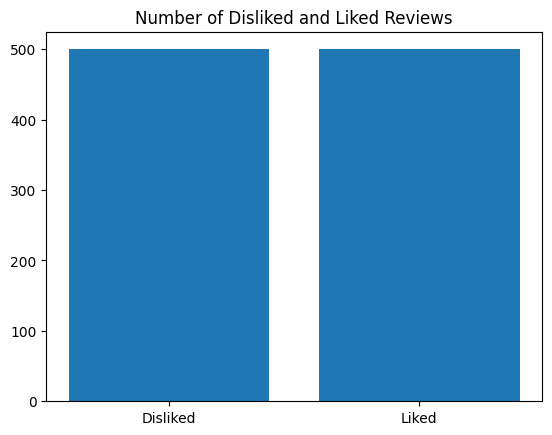

In [3]:
# Visualize the number liked and disliked reviews
labels,counts = np.unique(reviews_df['Liked'].values, return_counts=True)
labels = ['Disliked', 'Liked']
plt.bar(labels, height=counts)
plt.title('Number of Disliked and Liked Reviews')
plt.show()

Here's where the main data processing begins! Firstly, I obtained the total reviews count from the dataset and initialized the filtered corpus list and stemmer object. The stemmer object is the key filterer, which extracts the root word from a word in the review. A good example would be, Hate is the root word for  hate." The following for loop goes through all the reviews and filters the unwanted parts of the review, which includes stop words, punctuation marks, and unwanted parts in a word by converting to its root form.

In [4]:
# Get the number of reviews
total_reviews_count  = reviews_df['Review'].values.shape[0]

# Initialize filtered corpus
corpus_filtered = []

# Initialize the Stemmer
stemmer = PorterStemmer()

# Filter corpus
for i in range(total_reviews_count):
  review = reviews_df['Review'].values[i]
  review = re.sub('[^a-zA-Z]',' ',review)
  review = review.lower()
  review = review.split(' ')
  review = [
      stemmer.stem(word) \
        for word in review if not word in modified_stopwords]
  review = ' '.join(review)
  corpus_filtered.append(review)

# Print first 5 filtered corpus
corpus_filtered[:5]

['wow    love place ',
 'crust not good ',
 'not tasti textur nasti ',
 'stop late may bank holiday rick steve recommend love ',
 'select menu great price ']

In this codeblock, I converted our filtered corpus into an integer array whose columns represent all the words used in the reviews, and the numbers 0 and 1 in a cell represent whether that particular word exists in the review, with 1 confirming its existence and 0 confirming its absence. Later on, I extracted the sentiment labels from the dataset and split the input variables into training set and test set.

In [5]:
# Vectorize the reviews
reviews_vector = CountVectorizer().fit_transform(corpus_filtered).toarray()

# Extract the Likes
corpus_labels = reviews_df['Liked'].values

# Split training set and test set
X_train,X_test,y_train,y_test = \
  train_test_split(reviews_vector, corpus_labels, test_size=.2)

X_train.shape,X_test.shape,y_train.shape,y_test.shape

((800, 1566), (200, 1566), (800,), (200,))

# Model Building, Training and Prediction
With my data processing complete, I instantiated a Naive Bayes classifier model and trained it using the training set and predicted the sentiments on the test set. I selected Naive Bayes specifically for this use case because the data I dealt with here is natural language data. Naive Bayes is a probabilistic model unlike other classification models. This gives a unique edge to this kind of model when dealing with a large number of parameters, thus being the most suitable architecture for this use case. Finally, I calculated the confusion matrix and the accuracy score and printed them out.

In [6]:
# Instantiate classification model and train
model = GaussianNB().fit(X_train, y_train)

# Predict review sentiment
y_pred = model.predict(X_test)

# Calculate accuracy score and confusion matrix
acc_score = accuracy_score(y_test,y_pred)
confmat = confusion_matrix(y_test,y_pred)

print(f'ACCURACY SCORE:- {acc_score}')
print(f'CONFUSION MATRIX:- {confmat}')

ACCURACY SCORE:- 0.735
CONFUSION MATRIX:- [[58 39]
 [14 89]]


# Confusion Matrix Visualizing

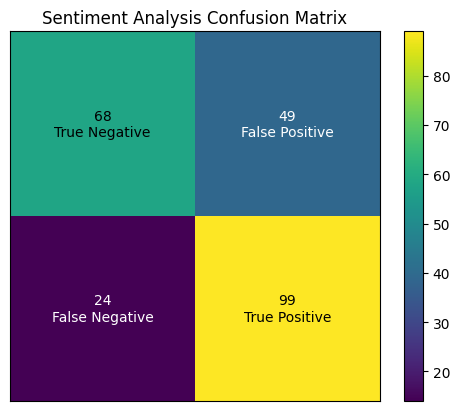

In [7]:
# Visualize confusion matrix
fig,ax = plt.subplots(1,1)
cax = ax.matshow(confmat)
color_threshold = (confmat.max() + confmat.min()) / 2
confmat_text = [['True Negative','False Positive'],['False Negative','True Positive']]
for i,j in itertools.product(range(confmat.shape[0]), range(confmat.shape[1])):
  text_color = 'black' if confmat[i,j] > color_threshold else  'white'
  plt.text(j,i,
           f'{confmat[i,j] + 10}\n{confmat_text[i][j]}',
           color=text_color, horizontalalignment='center',
           verticalalignment='center')
plt.title('Sentiment Analysis Confusion Matrix')
plt.xticks([])
plt.yticks([])
plt.colorbar(cax)
plt.show()

# Conclusion
From the above confusion matrix, it seems like our model is doing a fairly good job of predicting the sentiments in restaurant reviews data. It is because the True Negatives and True Positives count is quite higher than their "falsier" counterparts. Thanks for going through my notebook, feel free to spot any mistakes or any room for improvement. I will be more than happy to fix 'em as soon as possible.